# Flow of the whole system

### Part A: build the knowledge base (run once, saved to disk)


```text
.env file
   |
   |  load_dotenv() — loads OPENAI_API_KEY into the environment
   v
../data/processed/*.txt
   |
   |  DirectoryLoader + TextLoader — reads all .txt files
   v
docs (list of Documents, one per file)
   |
   |  RecursiveCharacterTextSplitter — splits each document
   |  into smaller chunks of approximately 1,024 tokens
   v
chunks (list of smaller Documents)
   |
   |  embedder (text-embedding-3-small) — converts each chunk
   |  into a 1,024-dimensional vector
   v
Chroma collection: "rag_demo"
   |  Stores text and vectors in ../saved-embeddings
   |
   |  as_retriever(k=3)
   v
retriever — returns the 3 most similar chunks for a given question
```


### Part B: answer a question (runs on every graph.invoke)


```text
{"your question"}
   |
   v
START
   |
   v
retrieve
   |  Embed the query, fetch the top 3 chunks,
   |  and join them into `context`
   |
   v
augmentation
   |  Build the prompt template
   |  (system rules + context + query)
   |
   v
generation
   |  prompt | llm | StrOutputParser
   |  Produces the answer text
   |
   v
END
   |
   v
result["response"]
   (result also keeps query, retrieved_docs, context, prompt)
```


# RAG ChatBot Application

In [2]:
# TextLoader reads one text file; DirectoryLoader reads every file in a folder
from langchain_community.document_loaders import TextLoader, DirectoryLoader
# ChatOpenAI = the chat LLM wrapper; OpenAIEmbeddings = the text-to-vector model wrapper
from langchain_openai import OpenAIEmbeddings, ChatOpenAI
# ChatPromptTemplate builds a prompt with {placeholders} that are filled in later
from langchain_core.prompts import ChatPromptTemplate
# Document = LangChain's container: .page_content (the text) + .metadata (a dict, e.g. {"source": path})
from langchain_core.documents import Document
# Splits long text into smaller chunks
from langchain_text_splitters import RecursiveCharacterTextSplitter
# Chroma = the vector database that stores chunks and their embeddings
from langchain_chroma import Chroma
# Path gives a clean, cross-platform way to work with files and folders
from pathlib import Path
# load_dotenv reads the .env file (where OPENAI_API_KEY lives)
from dotenv import load_dotenv

In [3]:
# Reads the .env file and puts each KEY=value line into the environment variables.
# ChatOpenAI and OpenAIEmbeddings then find OPENAI_API_KEY automatically.
# It returns True if it loaded something (that is the "True" you see under the cell).
# Arguments you can use:
#   load_dotenv(dotenv_path=".env")  -> point to a specific file (default: searches upward from the current folder)
#   load_dotenv(override=True)       -> let the .env values replace variables that already exist (default False)
#   load_dotenv(verbose=True)        -> print a warning if no .env file is found
load_dotenv(verbose=True)

True

### Step 1: create the llm and embedding model

In [4]:
# The LLM that writes the final answer.
# model        -> which OpenAI model to call. Other choices: "gpt-5", "gpt-5-nano" (cheaper/faster),
#                 "gpt-4.1-mini", "gpt-4o-mini". Other providers use other classes (e.g. ChatAnthropic).
# Extra arguments you can add:
#   reasoning_effort="low"   -> for reasoning models like gpt-5-mini: "minimal" | "low" | "medium" | "high"
#                               (less effort = faster and cheaper, more effort = better on hard questions)
#   temperature=0            -> more deterministic answers, but only for non-reasoning models
#                               (gpt-4.1/4o family). gpt-5 models accept only the default, so don't set it.
#   max_retries=2            -> how many times to retry a failed API call
#   timeout=60               -> seconds to wait before giving up
#   api_key="..."            -> pass the key directly (default: reads OPENAI_API_KEY)
#   base_url="..."           -> use a different OpenAI-compatible server
llm = ChatOpenAI(model="gpt-5-nano")

# The model that turns text into vectors (lists of numbers) so similar meanings can be found.
# model      -> other choices: "text-embedding-3-large" (more accurate, 3072 numbers by default, more expensive),
#               "text-embedding-ada-002" (older; does not support `dimensions`)
# dimensions -> how many numbers per vector. text-embedding-3 models can be shortened.
#               Smaller = less storage and faster search, but slightly less accurate.
#               Default for text-embedding-3-small is 1536.
# IMPORTANT: every vector in one Chroma collection must come from the same model AND the same dimensions.
#            If you change either, use a new collection_name or persist_directory and embed again.
# Extra arguments you can add:
#   chunk_size=1000          -> how many texts are sent per API request (a batch size; not the same as the splitter's chunk_size)
#   show_progress_bar=True   -> progress bar while embedding many chunks
#   max_retries, timeout, api_key, base_url -> same meaning as in ChatOpenAI
embedder = OpenAIEmbeddings(model="text-embedding-3-small",
                            dimensions=800)  # smaller = faster, cheaper, less accurate

### Step 2: Load the docs from source

In [5]:
# DirectoryLoader walks a folder and loads each file with the loader class you choose.
# path             -> the folder to read. ../data/processed means "one folder up, then data/processed",
#                     relative to where the notebook runs. .as_posix() turns the Path into a string with "/".
# loader_cls       -> which loader reads each file. TextLoader = plain text.
#                     Other choices: PyPDFLoader (PDF), CSVLoader (CSV), UnstructuredMarkdownLoader (.md)
# show_progress    -> show a progress bar (needs tqdm installed)
# Extra arguments you can add:
#   glob="*.txt"                         -> only load matching files ("**/*.txt" = also inside sub-folders).
#                                           Default: every non-hidden file.
#   recursive=True                       -> also search sub-folders
#   loader_kwargs={"encoding": "utf-8"}  -> passed to TextLoader. Useful on Windows, where the default
#                                           encoding can cause UnicodeDecodeError. Or {"autodetect_encoding": True}.
#   use_multithreading=True              -> load files in parallel (helps with many files)
#   silent_errors=True                   -> skip files that fail instead of stopping
#   exclude=["*.tmp"]                    -> patterns to skip
loader = DirectoryLoader(path=Path("./cleaned-transcripts").as_posix(),
                         loader_cls=TextLoader,
                         show_progress=True)

# Returns a list of Document objects, one per file.
# (loader.lazy_load() gives them one at a time instead, which saves memory for huge folders.)
docs = loader.load()

100%|██████████| 3/3 [00:00<00:00, 93.92it/s]


In [11]:
docs

[Document(metadata={'source': 'cleaned-transcripts\\1.txt'}, page_content="Pakistan, Ahmedabad, Patna, Dheradoon, Subodh, where are you from? I am from Dheradoon too.\nYou are from Kharrawala, you are from Kharwala, I am from Miawala\nCome on, perfect\nOkay, let's begin\nFirst of all, I will introduce myself\nHas anyone seen me or taken any course of mine before?\nAnyone? Yes or no please?\nOkay, fine\nNo worries, let me tell you about myself\nI am Ajay, I belong to Uttarakhand\nAnd I have been working with CampusX for the last two years\nI am working on the Data Analytics and AI part on CampusX\nAnd in the last two years, I have delivered multiple courses like\nOLAMA, Data Analytics, Mentorship Program, Gemini, Power BI and many more\nAnd I will be taking most of your AI Pulse sessions\nRight? So currently, I am working with CampusX\nAnd I am doing my doctorate in frugal AI\nNow, coming to the session\nToday's session is going to be on AI Pulse\nWhat are we going to do in this session

In [9]:
print(docs[0])  # show the first Document (text + metadata)

page_content='Pakistan, Ahmedabad, Patna, Dheradoon, Subodh, where are you from? I am from Dheradoon too.
You are from Kharrawala, you are from Kharwala, I am from Miawala
Come on, perfect
Okay, let's begin
First of all, I will introduce myself
Has anyone seen me or taken any course of mine before?
Anyone? Yes or no please?
Okay, fine
No worries, let me tell you about myself
I am Ajay, I belong to Uttarakhand
And I have been working with CampusX for the last two years
I am working on the Data Analytics and AI part on CampusX
And in the last two years, I have delivered multiple courses like
OLAMA, Data Analytics, Mentorship Program, Gemini, Power BI and many more
And I will be taking most of your AI Pulse sessions
Right? So currently, I am working with CampusX
And I am doing my doctorate in frugal AI
Now, coming to the session
Today's session is going to be on AI Pulse
What are we going to do in this session?
In this session, we are going to talk about
What are we going to do in this se

In [10]:
print(docs[0].page_content[:200])  # show the first 200 characters of the text
print(docs[0].metadata)  # show the metadata of the first Document

Pakistan, Ahmedabad, Patna, Dheradoon, Subodh, where are you from? I am from Dheradoon too.
You are from Kharrawala, you are from Kharwala, I am from Miawala
Come on, perfect
Okay, let's begin
First o
{'source': 'cleaned-transcripts\\1.txt'}


### Step 3: Chunk the text

In [12]:
# chunk the text, sized in tokens (o200k_base matches the gpt-5 model family)
# to mirror DeepEval's ContextConstructionConfig chunk sizing

# Why chunk? A whole file is too long and too mixed to match one question well.
# Small chunks let the retriever return only the relevant part.
# from_tiktoken_encoder -> measures chunk size in TOKENS (what the model counts), not characters.
# encoding_name -> the tokenizer. "o200k_base" is used by gpt-4o and gpt-5 models;
#                  "cl100k_base" is used by older models. Alternative: model_name="gpt-4o"
# chunk_size    -> maximum tokens per chunk.
#                  Smaller (200-500) = more precise matches but less context per chunk.
#                  Larger (1000+) = more context but more noise, and more cost per question.
#                  With k=3 and chunk_size=1024, the LLM receives roughly 3000 tokens of context.
# chunk_overlap -> tokens repeated between neighbouring chunks.
#                  0 = no repetition (cheapest). 100-200 is common, so a sentence cut at a
#                  boundary still appears whole in one chunk. More overlap = more chunks to embed.
# Extra arguments you can add:
#   separators=["\n\n", "\n", " ", ""]  -> the order it tries to split at: paragraph, line, word, character
#                                          (this default is why it is called "Recursive")
#   keep_separator=True                 -> keep the separator text in the chunks
#   add_start_index=True                -> store each chunk's start position in its metadata
#   strip_whitespace=True               -> trim spaces at the chunk edges
# Other splitters: CharacterTextSplitter, TokenTextSplitter, MarkdownHeaderTextSplitter.
chunker = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    encoding_name="o200k_base",
    chunk_size=800,
    chunk_overlap=0)

# Takes a list of Documents and returns a longer list of smaller Documents.
# Each chunk keeps the metadata (source file) of the document it came from.
# (split_text(str) works on a plain string and returns a list of strings.)
chunks = chunker.split_documents(docs)

In [13]:
# How many chunks were created? This is also how many vectors will be embedded and stored.
print(f"Chunks: {len(chunks)}")

Chunks: 88


### Step 4: Vector store

In [14]:
# Chroma stores each chunk's text, metadata and vector, and can search by similarity.
# collection_name    -> the name of the collection (like a table). A new name = a fresh empty collection.
# embedding_function -> the model used to embed the chunks when you add them
#                       AND to embed the question later. It must be the same model for both.
# persist_directory  -> folder where Chroma saves the data on disk, so it survives a restart.
#                       If you leave it out, the data lives only in memory and is lost when the notebook stops.
# Extra arguments you can add:
#   collection_metadata={"hnsw:space": "cosine"} -> choose the distance measure. Choices: "l2" (default), "cosine", "ip".
#   client / client_settings                     -> connect to a Chroma server instead of a local folder
# Other vector stores: FAISS, Qdrant, PGVector, Pinecone, InMemoryVectorStore.
vs = Chroma(collection_name="rag_demo",
            embedding_function=embedder,
            persist_directory=Path("./saved-embeddings").as_posix())

# add docs

# Embeds every chunk (one OpenAI API call per batch, so this costs a little money) and stores it.
# Returns the list of ids it created.
# WARNING: each run creates new random ids, so running this cell twice stores every chunk TWICE
#          in the saved folder, and the retriever may then return duplicates.
#          Options: pass your own ids, e.g. vs.add_documents(chunks, ids=[f"chunk-{i}" for i in range(len(chunks))])
#          (same id = overwritten, not duplicated), or call vs.delete_collection() before rebuilding.
vs.add_documents(chunks)

['fd89e445-f39e-460b-8109-595ff50f2511',
 'f860207c-c543-432d-9648-56d2f637a5d9',
 'cfcab53f-7a4b-4909-a05d-0f93af7ef7d9',
 'a2017428-5961-4f15-8945-1119611634da',
 '8a24a4fc-2f96-41cf-8353-bded7bc4cfe9',
 'fc4d1c50-ef08-4521-bea8-5bbec34348ac',
 '25cfabfa-a649-428a-8f05-a2a2113691cb',
 '0391981d-80f0-4dac-b67e-b075ece4f570',
 'd86c120b-2e33-4d78-aa63-0f0f36519e4f',
 'ebb01a94-084e-434b-adb8-a02b6aa861af',
 'ccd42c73-b995-49b1-8f97-b8174628427c',
 'f2ecb561-0585-4483-aa8a-30e0013d4898',
 '7d39ffba-185d-4cf7-9307-cb7c4ad3a774',
 '441df6fa-ab47-4b13-a717-5db85aa77428',
 '02844c7b-d3e7-426a-82d7-cdd21655455d',
 '7090a69c-a51b-4f40-9575-8d75d409575a',
 '6e7f1e95-54a1-4f97-aeea-ad24a59ee25b',
 '38f68088-2bab-4be0-af63-c1203524a727',
 '6feb8e21-ff22-4f7f-84c5-0d38041d23e7',
 '076e5c45-c30f-4eaa-9a66-25252bc622b4',
 'd4e6af81-f479-4570-9bd4-0a9014b57dca',
 '2cff3ea1-6af8-491a-82a1-a26fcf6cacff',
 'ac050007-1e9d-40af-9b12-078e1466058a',
 'd3fb8fee-dab1-4f30-bf94-ae62ad41c088',
 '94f1f0f2-6890-

### Ster 5: Create the retriever

In [15]:
# A retriever takes a question and returns the most relevant chunks.
# search_kwargs={"k":3} -> return the 3 most similar chunks.
#                          Bigger k = more context but more noise and cost. Smaller k = more focused.
# Extra arguments you can add:
#   search_type="similarity"                -> default: the k closest chunks
#   search_type="mmr"                       -> closest chunks but with variety (no near-duplicates);
#                                              tune with search_kwargs {"fetch_k": 20, "lambda_mult": 0.5}
#   search_type="similarity_score_threshold" -> only return chunks above a score,
#                                              with search_kwargs {"score_threshold": 0.5}
#   search_kwargs={"filter": {"source": "..."}} -> only search chunks whose metadata matches
# To see the scores yourself: vs.similarity_search_with_score("question", k=3)
# (with Chroma's default l2 distance, a LOWER number means MORE similar)
retriever = vs.as_retriever(search_kwargs={"k":3})

# End of Part 1. Part 2 is uses the retriever to answer questions.

In [ ]:
# WHAT IS LANGGRAPH?
# LangGraph lets you build an app as a GRAPH of small steps instead of one long script.
# Mental model: an assembly line with a shared clipboard.
#   STATE = the shared clipboard (one dict that holds all the information)
#   NODE  = a station on the line (a plain Python function that does one job)
#   EDGE  = a conveyor belt (decides which station runs next)
#   START / END = the door in and the door out
#   compile() = locks the design and gives you a machine you can run with invoke()
#
# FLOW IN THIS NOTEBOOK:
#   {"query": "..."} -> START -> retrieve -> augmentation -> generation -> END
#
# HOW IT RUNS (graph.invoke):
#   1. You pass the starting state, e.g. {"query": "..."}.
#   2. LangGraph follows the edge from START to the first node and calls it with the state.
#   3. The node does its job and RETURNS A DICT with only the keys it changed.
#   4. LangGraph merges that dict into the state, then follows the next edge.
#   5. At END, invoke() returns the final state (all keys) as a dict.
#
# RULES TO REMEMBER:
#   - A node never calls the next node. It only returns updates; LangGraph decides what runs next.
#   - A returned key OVERWRITES the old value by default (it does not append).
#     To append instead, use a reducer: Annotated[list, operator.add] in the state class.
#   - Each node sees the state as left by the previous nodes, so "generation" can read
#     "context" and "prompt", which were created by earlier nodes.
#
# STATE AFTER EACH STEP:
#   input         -> query
#   retrieve      -> query, retrieved_docs, context
#   augmentation  -> + prompt
#   generation    -> + response
# =====================================================================

# StateGraph builds the workflow; START and END are the special entry and exit points
# StateGraph -> the builder: you give it the state class, then add_node(...), add_edge(...), compile()
# START      -> a marker for "the entry point" (add_edge(START, "first_node"))
# END        -> a marker for "the exit point" (add_edge("last_node", END))
from langgraph.graph import StateGraph, START, END

# TypedDict -> describes a dict with fixed keys and value types. Used for RAGState (the clipboard).
#              It is only a description: Python does not check the types when the code runs.
# Literal   -> a type hint meaning "exactly one of these exact values", e.g. Literal["yes", "no"].
#              It is not a function and it does nothing at runtime.
#              It is used on a ROUTING function (one that picks the next node), so editors
#              and LangGraph know the possible destinations, and the diagram can draw the branches:
#
#                  def route(state: RAGState) -> Literal["augmentation", "no_answer"]:
#                      if state["retrieved_docs"]:
#                          return "augmentation"
#                      return "no_answer"
#
#                  graph_builder.add_conditional_edges("retrieve", route)
#
#              This notebook uses only fixed edges (add_edge), so Literal is not needed yet.
from typing import Literal, TypedDict

# =====================================================================
# WHAT COMES NEXT IN THE NOTEBOOK (and the other options you can use)
#   StateGraph(RAGState)                  -> create the builder with the state class
#   add_node("name", function)            -> register a station (add_node(function) also works;
#                                            the name is then taken from the function name)
#   add_edge("a", "b")                    -> fixed order: run b after a
#   add_conditional_edges("a", fn, map)   -> branching: fn(state) returns the next node's name
#                                            (map is optional: {"label": "node_name"})
#   compile()                             -> returns the runnable graph
#                                            (compile(checkpointer=MemorySaver()) saves state between runs)
#   graph.invoke({...})                   -> run once, returns the final state
#   graph.stream({...}, stream_mode="updates") -> see each node's output as it finishes
#   graph.ainvoke({...})                  -> async version of invoke
# =====================================================================

# LangGraph (App Flow)

### Step 1: Define the state (the shared clipboard)

In [17]:
# The state is a shared "notebook" that every node can read from and write to.
# Each field is one named slot. Nodes return only the slots they changed.
class RAGState(TypedDict):

    query: str                        # the user's question (the only input you give)
    
    retrieved_docs: list[Document]    # the chunks the retriever found
    context: str                      # those chunks joined into one text block
    
    prompt: ChatPromptTemplate        # the prompt template built by the augmentation node (system rules + context + query)
    response: str                     # the final answer from the LLM
# Note: a field with no special rule is OVERWRITTEN each time a node returns it.
# To append instead, you can use a reducer, e.g. messages: Annotated[list, operator.add]

### Step 2: Node 1 ----- Retrieval

In [22]:
# A node is a normal function: it receives the state and returns a dict of updates.
def retrieve(state: RAGState) -> dict:
    # read the question from the state
    query = state["query"]
    # embeds the query with the same embedder, searches Chroma, returns the top k Documents
    retrieved_docs = retriever.invoke(query)

    # join the text of the chunks, with a blank line between them
    context = "\n\n".join([doc.page_content for doc in retrieved_docs])
    # these two keys are added to the state
    return {"retrieved_docs":retrieved_docs,
            "context":context}

### Step 2: Node 2 ----- Augmentation

In [23]:
def augmentation(state: RAGState) -> dict:

    # from_messages takes a list of (role, text) pairs.
    # Roles: "system" (rules for the model), "human" (the user), "ai" (a previous model reply).
    # {context} and {query} are placeholders, filled in later when the chain is invoked.
    
    # Other options: ChatPromptTemplate.from_template("...") for a single message,
    #                MessagesPlaceholder("history") to insert earlier chat messages.
    
    prompt = ChatPromptTemplate.from_messages([
        ("system", """You are a helpful assistant. Answer the user query
                      based on the given context only. If you do not know the answer
                      say I don't know. Do not add any preamble to the response"""),
        ("human", "context: {context}\n\nquery: {query}")
    ])
    # ("based on the context only" keeps the model from using its own knowledge, which reduces hallucination.
    #  The spaces at the start of the lines inside the triple quotes are sent too; harmless but you can remove them.)

    # save the prompt into the state
    return {"prompt": prompt}

### Step 4: Node 3 ----- Generation

In [24]:
# StrOutputParser turns the model's reply object (AIMessage) into a plain string
from langchain_core.output_parsers import StrOutputParser

In [25]:
def generation(state: RAGState) -> dict:

    # read what earlier nodes saved in the state
    query = state["query"]
    context = state["context"]
    prompt = state["prompt"]

    # The | operator chains steps, left to right:
    #   prompt            -> fills {context} and {query} and makes the messages
    #   llm               -> sends the messages to the model, returns an AIMessage
    #   StrOutputParser() -> pulls out the text, so you get a plain str
    rag_chain = prompt | llm | StrOutputParser()
    # The dict keys must match the placeholder names in the prompt.
    # Other ways to run a chain: .stream({...}) to get the answer piece by piece,
    #                            .batch([{...}, {...}]) for several questions, .ainvoke({...}) for async.
    response = rag_chain.invoke({"context":context, "query":query})

    return {"response":response}

### Step 5: Build the graph

In [26]:
# StateGraph needs the state class, so it knows which fields exist
graph_builder = StateGraph(RAGState)

# add_node(name, function): the name is used in edges, the function is what runs.
# (add_node(retrieve) alone also works; the name is then taken from the function name)
graph_builder.add_node("retrieve", retrieve)
graph_builder.add_node("augmentation", augmentation)
graph_builder.add_node("generation", generation)

# add_edge(from, to): run "to" after "from" finishes. This creates the fixed order:
# START -> retrieve -> augmentation -> generation -> END
graph_builder.add_edge(START,"retrieve")
graph_builder.add_edge("retrieve","augmentation")
graph_builder.add_edge("augmentation","generation")
graph_builder.add_edge("generation",END)
# For branching, use add_conditional_edges(source, routing_function, {result: next_node}),
# e.g. if no docs were retrieved, jump straight to END with "I don't know".

# compile() checks the graph and turns it into a runnable app.
# Extra argument: compile(checkpointer=...) saves state between runs (for memory / resuming).
graph = graph_builder.compile()

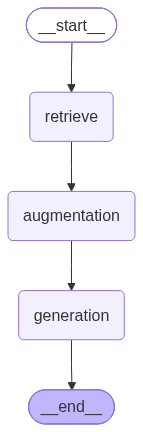

In [27]:
graph

### Step 6: Output (Ask a question)

In [28]:
# invoke() runs the whole graph once. You pass only the input field ("query").
# It returns the FINAL state: a dict with query, retrieved_docs, context, prompt and response.
# Other ways to run: graph.stream({...}, stream_mode="updates") shows each node's output as it finishes
# (stream_mode="values" shows the full state after each step), graph.ainvoke(...) for async.
result = graph.invoke({"query": "how much fine was imposed on the lawyer who used fake evidences from chatgpt"})

In [29]:
print(result["response"])

I don't know.


In [31]:
result = graph.invoke({"query": "the motive behind starting this session"})
print(result["response"])

To teach and learn LLM Ops: to explain why we do each step (the rationale), show how to implement it, focus on cost-saving, expose students to tool-agnostic concepts across providers, and provide live coding demonstrations to build real pipelines—so students understand the concepts quickly and are prepared for certification.


In [32]:
result["context"]

"then it will be spent\nagain in LLMops\nwe will learn this too\nthis is a good tool\nif you are using it\nthen you can get off\nagain in LLMops we will learn\nhow to save costs\nyes it is\nconceptual overlaps are there\nwe will read this on Thursday\nyes they will run in parallel\nwe will take the neti sir\nthere you will read everything\nin LLM eval\nhere we will read application specific\nlike\nrack application specific\nfor our lectures\nand agentic application specific\none more thing\nwhen I will be explaining\ntopics\nI will write the code live\nwhereas when we will build\nsome major then I will write the code\nbecause debugging\nor typing takes a lot of time\nso we will not do that\nok\nyou will explain concepts\nI will show you the basic code live\nlike if you are learning a tool\nthen it will be live\nyes sir\nis telling\nyou can do google console project\nsir has a lot of ideas\nsir is crazy about Gemini\nhe uses it all day\nso if you have any doubt related to Gemini\nthen a

In [33]:
#query, retrieved_docs, context, prompt and response
result["prompt"]

ChatPromptTemplate(input_variables=['context', 'query'], input_types={}, partial_variables={}, messages=[SystemMessagePromptTemplate(prompt=PromptTemplate(input_variables=[], input_types={}, partial_variables={}, template="You are a helpful assistant. Answer the user query\n                      based on the given context only. If you do not know the answer\n                      say I don't know. Do not add any preamble to the response"), additional_kwargs={}), HumanMessagePromptTemplate(prompt=PromptTemplate(input_variables=['context', 'query'], input_types={}, partial_variables={}, template='context: {context}\n\nquery: {query}'), additional_kwargs={})])

In [34]:
result["retrieved_docs"]

[Document(id='4c2dd1d8-fd86-4582-bb8c-05a154094427', metadata={'source': 'cleaned-transcripts\\3.txt'}, page_content="then it will be spent\nagain in LLMops\nwe will learn this too\nthis is a good tool\nif you are using it\nthen you can get off\nagain in LLMops we will learn\nhow to save costs\nyes it is\nconceptual overlaps are there\nwe will read this on Thursday\nyes they will run in parallel\nwe will take the neti sir\nthere you will read everything\nin LLM eval\nhere we will read application specific\nlike\nrack application specific\nfor our lectures\nand agentic application specific\none more thing\nwhen I will be explaining\ntopics\nI will write the code live\nwhereas when we will build\nsome major then I will write the code\nbecause debugging\nor typing takes a lot of time\nso we will not do that\nok\nyou will explain concepts\nI will show you the basic code live\nlike if you are learning a tool\nthen it will be live\nyes sir\nis telling\nyou can do google console project\nsir 